# Homework 4 - MTH 602 - Coding Questions

William Girard

Due Date: Monday, October 26th, 2026

## Chapter 3: Multivariate Gaussian Mixture Modeling

Problem context:  Probability mixture modeling is used throughout science and engineering.  For example, see a 
multi-component Gaussian mixture model for pulsar classification (https://arxiv.org/pdf/1205.6221, Fig. 2). 
In this assignment, the you will proceed from a 1-component to a 2-component mixture model, using diagnostics 
to check model correctness.  In class the basics of 2D Gaussians and mixture models were outlined.  To complete 
this assignment it may be helpful to consult the scikit-learn documentation on fitting GMMs from samples (https:
//scikit-learn.org/stable/modules/mixture.html).

The exercises use 2D data to explore Gaussian Mixture Models (GMMs). Hints given throughout this assignment 
will assume Python with scikit-learn and the following modules:

``` python
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
import numpy as np
```
Use the following function to generate ground-truth samples in Stages 1 and 2.

``` python
def sample_2d_gaussian(mu, Sigma, n, rng=None):
if rng is None:
 rng = np.random.default_rng()
return rng.multivariate_normal(mean=mu, cov=Sigma, size=n)
```

### Stage 1 — One Gaussian: MLE vs. GMM with 1 component

1. Visualization: Make a scatter plot of the samples

In [1]:
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
import numpy as np

In [2]:
def sample_2d_gaussian(mu, Sigma, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    return rng.multivariate_normal(mean=mu, cov=Sigma, size=n)

In [14]:
mu = [2, - 1]
sigma = [[2, 0.8],
         [0.8, 1]]

N = 1000
samples = sample_2d_gaussian(mu, sigma, N)
samples.shape

(1000, 2)

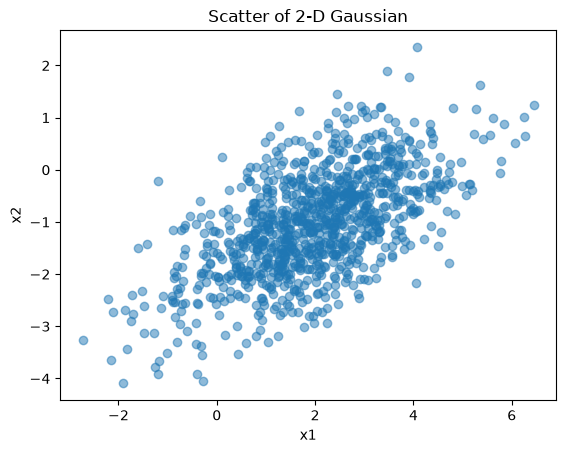

In [15]:
import matplotlib.pyplot as plt 

x_1 = samples[:, 0]
x_2 = samples[:, 1]
plt.scatter(x_1, x_2, alpha=0.5)
plt.title("Scatter of 2-D Gaussian")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

2. Analytic maximum-likelihood solution

In [36]:
# ground truth mean for x1 is 2
# ground truth mean for x2 is -1

mu_x1_MLE = np.mean(x_1)

mu_x2_MLE = np.mean(x_2)

print(f'Ground truth x1: {mu[0]} - MLE solution: {mu_x1_MLE}')
print(f'Ground truth x2: {mu[1]} - MLE solution: {mu_x2_MLE}')
mu_MLE = np.array([mu_x1_MLE,mu_x2_MLE])
mu_MLE

Ground truth x1: 2 - MLE solution: 1.9644662946304405
Ground truth x2: -1 - MLE solution: -1.0296938049628024


array([ 1.96446629, -1.0296938 ])

In [23]:
# ground truth variance for x1 is 2

product = 0
for x_i in x_1:

    product += (x_i - mu_x1_MLE)*(np.transpose(x_i - mu_x1_MLE))

var_MLE_1 = product/N
var_MLE_1

np.float64(2.0238555575307036)

In [24]:
product = 0
for x_i in x_2:

    product += (x_i - mu_x2_MLE)*(np.transpose(x_i - mu_x2_MLE))

var_MLE_2 = product/N
var_MLE_2

np.float64(0.9841355816802995)

In [25]:
product = 0
for x_i_1, x_i_2 in zip(x_1, x_2):

    product += (x_i_1 - mu_x1_MLE)*(np.transpose(x_i_2 - mu_x2_MLE))

var_MLE_12 = product/N
var_MLE_12

np.float64(0.8452713445084484)

In [29]:
cov_MLE = np.array([[var_MLE_1, var_MLE_12], 
                   [var_MLE_12, var_MLE_2]])
cov_MLE

array([[2.02385556, 0.84527134],
       [0.84527134, 0.98413558]])

In [31]:
g1 = GaussianMixture(n_components=1, covariance_type='full',
n_init=10, random_state=0).fit(samples)

In [37]:
u_gmm = g1.means_

l2_norm = np.linalg.norm(u_gmm-mu_MLE)

l2_norm

np.float64(1.4217791915866692e-15)

In [38]:
cov_gmm = g1.covariances_ 

l2_norm = np.linalg.norm(cov_gmm-cov_MLE)
l2_norm

np.float64(1.4142135631203034e-06)

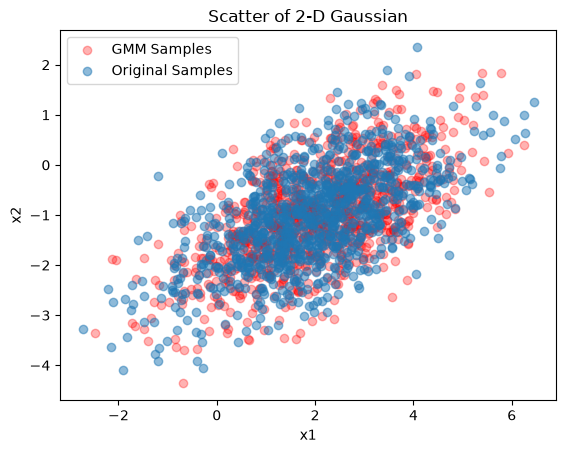

In [45]:
new_samples = g1.sample(N)
new_samples = new_samples[0]

import matplotlib.pyplot as plt 

x_1 = samples[:, 0]
x_2 = samples[:, 1]
plt.scatter(new_samples[:,0], new_samples[:, 1], color = 'red', alpha=0.3, label='GMM Samples')
plt.scatter(x_1, x_2, alpha=0.5, label='Original Samples')
plt.title("Scatter of 2-D Gaussian")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.show()